# SteadierComVA

In [ ]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

import reframed
from reframed.solvers.solution import Status

from warnings import warn
import sys


sys.path.append("../functions/")
import simulation.general as general
import simulation.steadiercom_fva


In [2]:
%load_ext autoreload
%autoreload 2

#### Load models and media

In [3]:
models_ecoli = general.load_models_guillen2021(all_38_strains=False)

INFO     | Loading models for Guillen et al (2021)...


In [4]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")
m9_compounds = media_db.query("medium == 'M9'").compound.values
env_m9 = reframed.Environment.from_compounds(m9_compounds)

In [5]:
env_m9.R_EX_glc__D_e = (-1000.0, np.inf)
env_m9

R_EX_ca2_e	-10.0	inf
R_EX_cl_e	-10.0	inf
R_EX_cobalt2_e	-10.0	inf
R_EX_cu2_e	-10.0	inf
R_EX_fe2_e	-10.0	inf
R_EX_fe3_e	-10.0	inf
R_EX_glc__D_e	-1000.0	inf
R_EX_h2o_e	-10.0	inf
R_EX_h_e	-10.0	inf
R_EX_k_e	-10.0	inf
R_EX_mg2_e	-10.0	inf
R_EX_mn2_e	-10.0	inf
R_EX_mobd_e	-10.0	inf
R_EX_na1_e	-10.0	inf
R_EX_nh4_e	-10.0	inf
R_EX_ni2_e	-10.0	inf
R_EX_o2_e	-10.0	inf
R_EX_pi_e	-10.0	inf
R_EX_so4_e	-10.0	inf
R_EX_zn2_e	-10.0	inf

#### Build community model

In [6]:
comm_model = reframed.Community(community_id="mutants",
                   models=models_ecoli.values(),
                   copy_models=True)
env_m9.apply(comm_model.merged_model,
             inplace=True,
             exclusive=True,
             )

### Test

In [7]:
solution = steadiercom_fva.SteadierCom_binary_search(comm_model)

Set parameter Username


INFO     | Set parameter Username


Academic license - for non-commercial use only - expires 2027-06-05


INFO     | Academic license - for non-commercial use only - expires 2027-06-05


	 0: last_feasible=0, testing value=2
	 1: last_feasible=0, testing value=1.0
	 2: last_feasible=0, testing value=0.5
	 3: last_feasible=0.5, testing value=0.75
	 4: last_feasible=0.5, testing value=0.625
	 5: last_feasible=0.5, testing value=0.5625
	 6: last_feasible=0.5, testing value=0.53125
	 7: last_feasible=0.5, testing value=0.515625
	 8: last_feasible=0.515625, testing value=0.5234375
	 9: last_feasible=0.5234375, testing value=0.52734375
	 10: last_feasible=0.52734375, testing value=0.529296875
	 11: last_feasible=0.529296875, testing value=0.5302734375


In [9]:
solution

(Community growth: 0.5302734375
 mutant_panZ	0.9168544874383716
 mutant_bioF	0.0
 mutant_bioC	0.0
 mutant_icd	0.0
 mutant_bioH	0.0
 mutant_cysW	0.08314551256162828
 mutant_panD	0.0,
 <Status.OPTIMAL: 'Optimal'>)

### Abundance envelopes

In [11]:
abundance_envelope_df = pd.read_csv("../output/Guillen2021/results_steadiercom/abundance_envelopes/fva_results_1000_glucose.tsv",sep="\t")
abundance_envelope_df


,member,l,u,obj_frac,w_e,growth,growth*obj_frac
0,mutant_panZ,0.0,0.999969,1.0,0.001,0.828125,0.828125
1,mutant_bioF,0.0,0.999953,1.0,0.001,0.828125,0.828125
2,mutant_bioC,0.0,0.999953,1.0,0.001,0.828125,0.828125
3,mutant_icd,0.0,0.110613,1.0,0.001,0.828125,0.828125
4,mutant_bioH,0.0,0.999953,1.0,0.001,0.828125,0.828125
...,...,...,...,...,...,...,...
345,mutant_bioC,0.0,1.000000,0.0,0.010,0.082031,0.000000
346,mutant_icd,0.0,1.000000,0.0,0.010,0.082031,0.000000
347,mutant_bioH,0.0,1.000000,0.0,0.010,0.082031,0.000000
348,mutant_cysW,0.0,1.000000,0.0,0.010,0.082031,0.000000


#### Plot

In [26]:
def abundance_envelope_plot(plot_df,x="growth*obj_frac",hue="w_e",palette="Set2",ax=None,ylabel="$X^k$",xlabel=None,legend=True):
    
    ax_given = isinstance(ax,plt.Axes)
    
    if not ax_given:
        fig, ax = plt.subplots(1,1)

    hue_order = sorted(plot_df[hue].unique())
    colors = sns.color_palette(palette, n_colors=len(hue_order))
    palette_dict = dict(zip(hue_order, colors))

    ax = sns.lineplot(plot_df,x=x,y="u",hue=hue,ax=ax,hue_order=hue_order, palette=palette_dict,legend=legend)
    if legend:
        sns.move_legend(ax, 
                        "upper left",
                        bbox_to_anchor=(1.0, 1.0),
                        )
    ax = sns.lineplot(plot_df,x=x,y="l",hue=hue,ax=ax,hue_order=hue_order, palette=palette_dict,legend=False)

    df = plot_df.query("obj_frac == 1")
    for i, row in df.iterrows():
        ax.vlines(x=row[x], ymin=row.l, ymax=row.u,color=palette_dict[row[hue]], alpha=.7, linewidth=1.5)


    ax.set_ylabel(ylabel)
    ax.set_xlabel(x if xlabel is None else xlabel)

    if ax_given:
        return ax
    
    return fig, ax


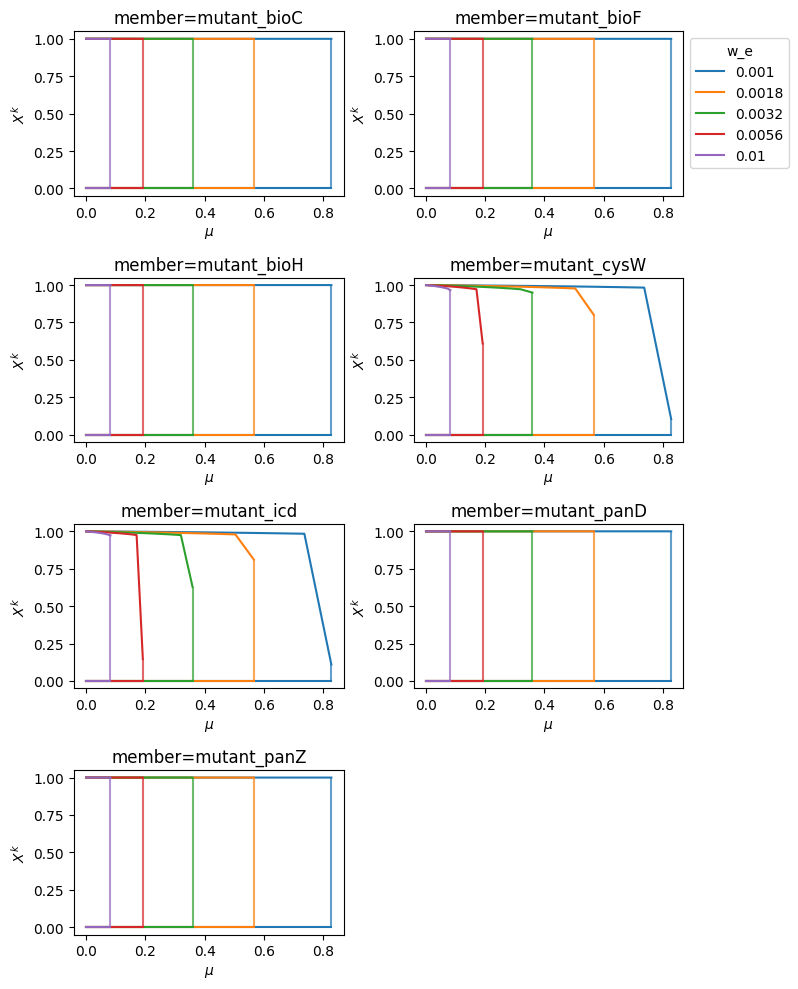

In [15]:

merged_df = abundance_envelope_df.copy()
fig, axs = plt.subplots(4,2,figsize=(8,10))

axs_flat = axs.flatten()
for ax,member in zip(axs_flat,merged_df.member.sort_values().unique()):
    plot_df = merged_df.query(f"member == '{member}'").copy()

    ax = abundance_envelope_plot(plot_df,x="growth*obj_frac",hue="w_e",palette="tab10",xlabel="$\mu$",ax=ax,legend= (member=="mutant_bioF"))
    ax.set_title(f"member={member}")

axs_flat[-1].set_axis_off()
plt.tight_layout()

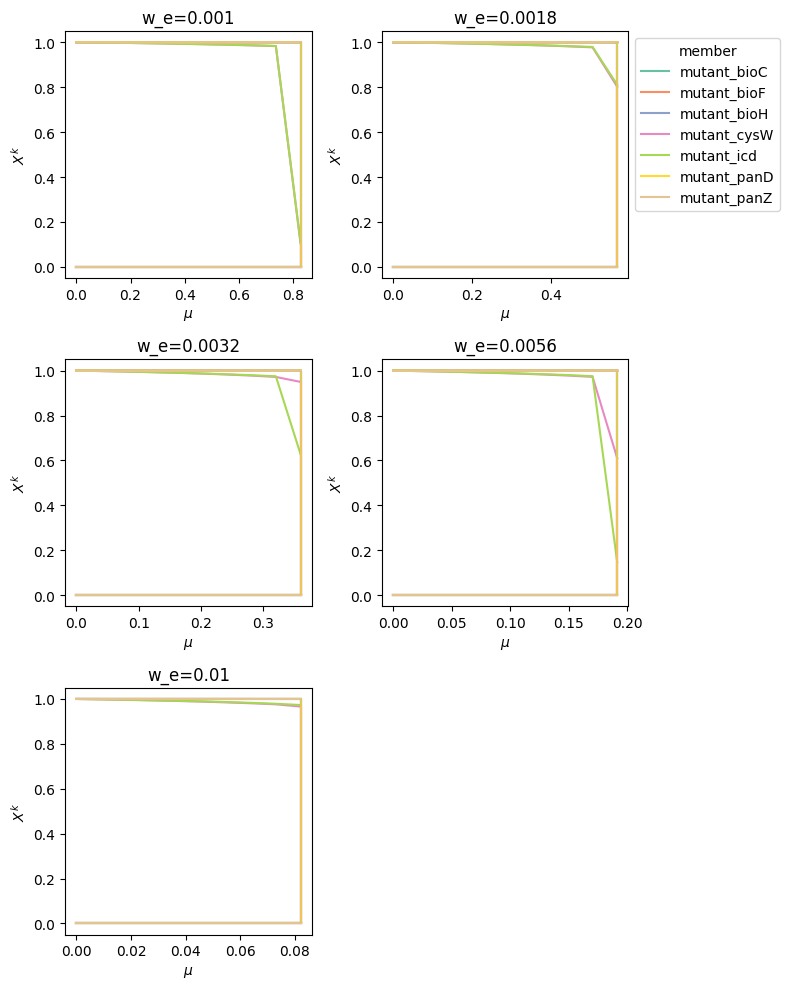

In [14]:
fig, axs = plt.subplots(3,2,figsize=(8,10))

axs_flat = axs.flatten()
for ax,w_e in zip(axs_flat,merged_df.w_e.sort_values().unique()):
    plot_df = merged_df.query(f"w_e == {w_e}").copy()

    ax = abundance_envelope_plot(plot_df,x="growth*obj_frac",hue="member",palette="Set2",xlabel="$\mu$",ax=ax,legend= (w_e==0.0018))
    ax.set_title(f"w_e={w_e}")
axs_flat[-1].set_axis_off()
plt.tight_layout()

### Abundance envelopes with changing w_R

In [ ]:
abundance_envelope_df = pd.read_csv("../output/Guillen2021/results_steadiercom/abundance_envelopes/fva_results_1000_glucose_wr.tsv",sep="\t")
abundance_envelope_df


,member,l,u,obj_frac,w_e,growth,growth*obj_frac
0,mutant_panZ,0.0,0.999969,1.0,0.001,0.828125,0.828125
1,mutant_bioF,0.0,0.999953,1.0,0.001,0.828125,0.828125
2,mutant_bioC,0.0,0.999953,1.0,0.001,0.828125,0.828125
3,mutant_icd,0.0,0.110613,1.0,0.001,0.828125,0.828125
4,mutant_bioH,0.0,0.999953,1.0,0.001,0.828125,0.828125
...,...,...,...,...,...,...,...
345,mutant_bioC,0.0,1.000000,0.0,0.010,0.082031,0.000000
346,mutant_icd,0.0,1.000000,0.0,0.010,0.082031,0.000000
347,mutant_bioH,0.0,1.000000,0.0,0.010,0.082031,0.000000
348,mutant_cysW,0.0,1.000000,0.0,0.010,0.082031,0.000000


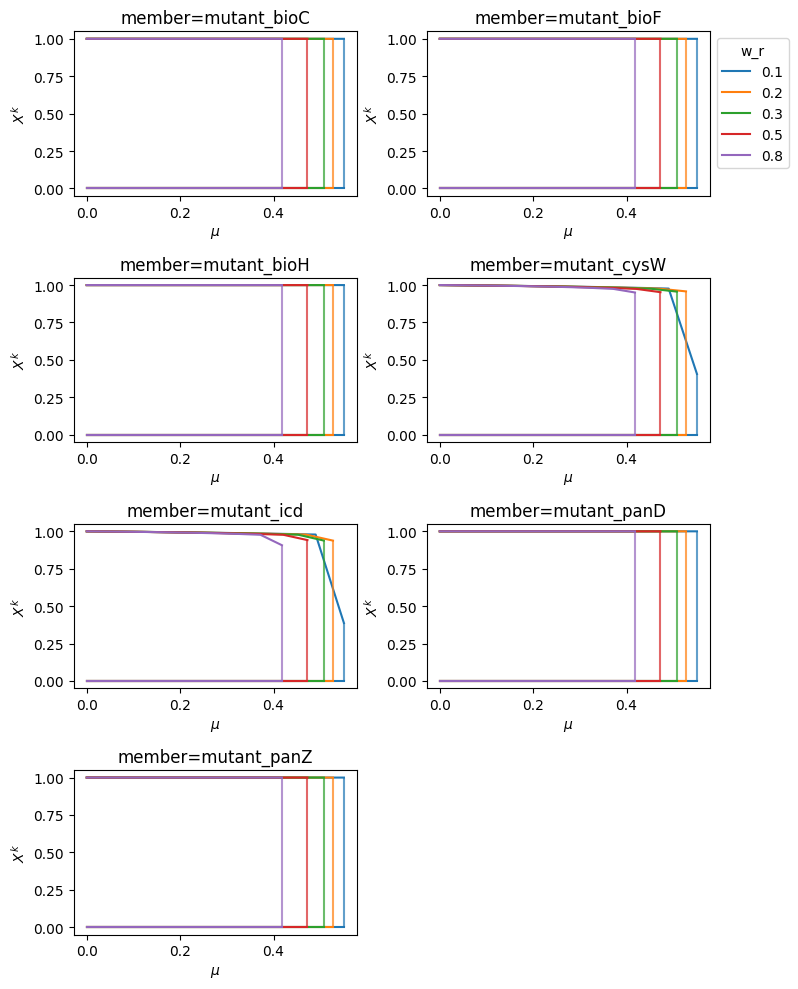

In [31]:

merged_df = abundance_envelope_df.copy()
fig, axs = plt.subplots(4,2,figsize=(8,10))

axs_flat = axs.flatten()
for ax,member in zip(axs_flat,merged_df.member.sort_values().unique()):
    plot_df = merged_df.query(f"member == '{member}'").copy()

    ax = abundance_envelope_plot(plot_df,x="growth*obj_frac",hue="w_r",palette="tab10",xlabel="$\mu$",ax=ax,legend= (member=="mutant_bioF"))
    ax.set_title(f"member={member}")

axs_flat[-1].set_axis_off()
plt.tight_layout()

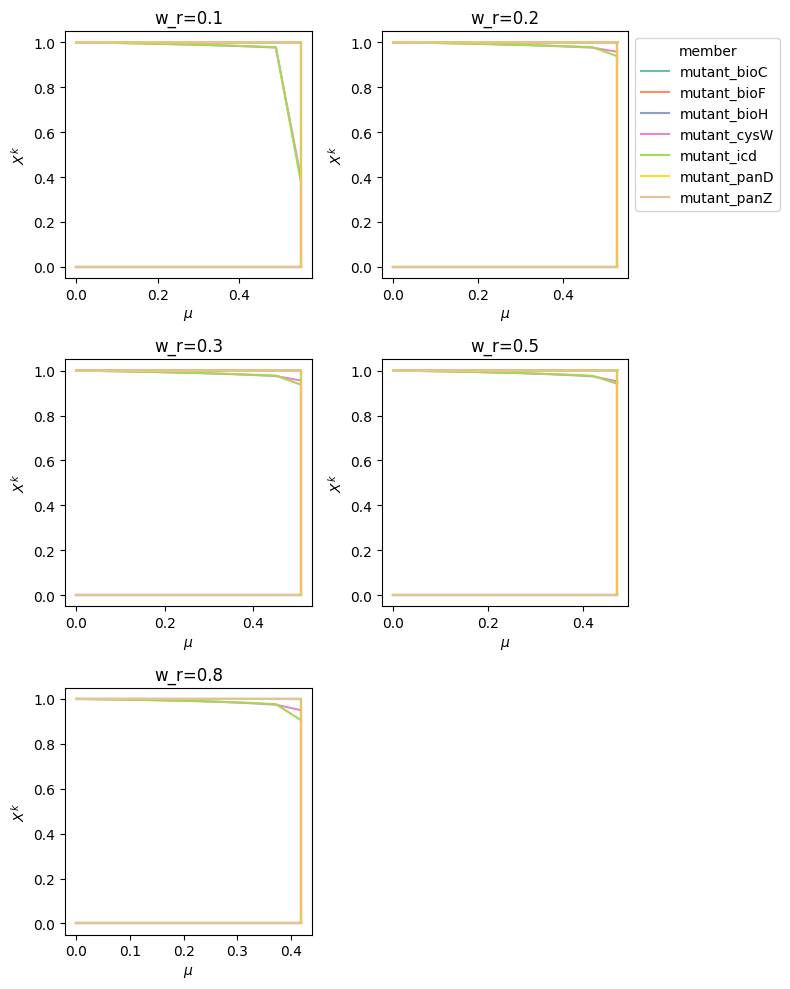

In [33]:
fig, axs = plt.subplots(3,2,figsize=(8,10))

axs_flat = axs.flatten()
for ax,w_r in zip(axs_flat,merged_df.w_r.sort_values().unique()):
    plot_df = merged_df.query(f"w_r == {w_r}").copy()

    ax = abundance_envelope_plot(plot_df,x="growth*obj_frac",hue="member",palette="Set2",xlabel="$\mu$",ax=ax,legend= (w_r==0.2))
    ax.set_title(f"w_r={w_r}")
axs_flat[-1].set_axis_off()
plt.tight_layout()

### Higher resolution abundance envelopes

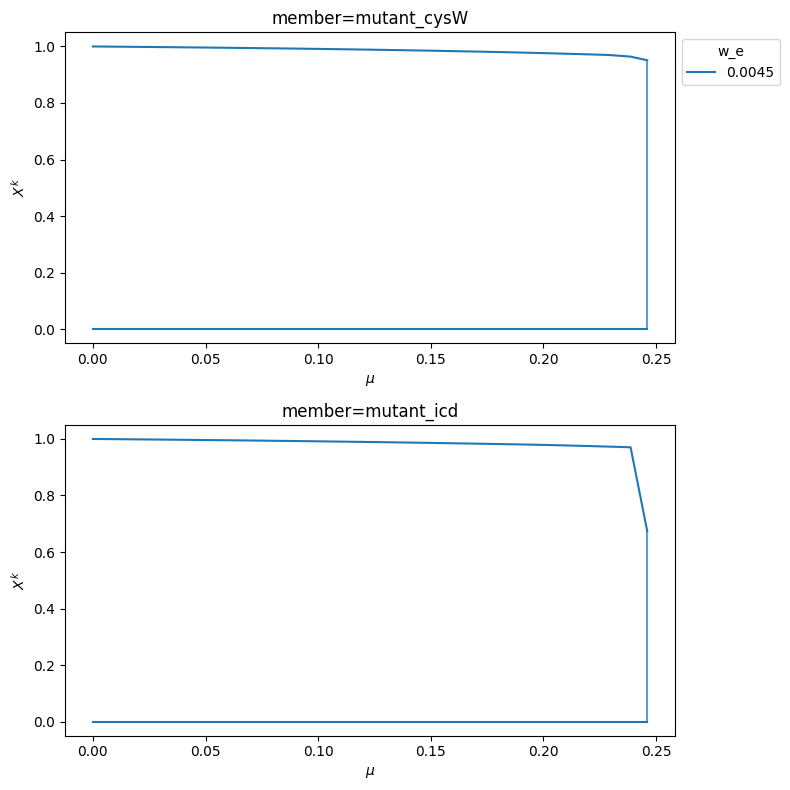

In [ ]:

merged_df = pd.concat(sols_unique)
merged_df["growth*obj_frac"]= merged_df.growth*merged_df.obj_frac
fig, axs = plt.subplots(2,1,figsize=(8,8))

axs_flat = axs.flatten()
for ax,member in zip(axs_flat,["mutant_cysW","mutant_icd"]):
    plot_df = merged_df.query(f"member == '{member}'").copy()

    ax = abundance_envelope_plot(plot_df,x="growth*obj_frac",hue="w_e",palette="tab10",xlabel="$\mu$",ax=ax,legend= (member=="mutant_cysW"))
    ax.set_title(f"member={member}")


plt.tight_layout()

## SteadierCom sampling results

In [34]:
abundance = pd.read_csv("../output/Guillen2021/results_steadiercom/results_we_test/0_0025__abundance.tsv",sep="\t")
abundance_filled = (
    abundance
        .pivot(index=["sample","community","medium"],columns="member",values="relative_abundance")
        .fillna(0)
        .stack()
        .reset_index()
        .rename(columns={0:"relative_abundance"}
                ))

In [35]:
abundance2 = pd.read_csv("../output/Guillen2021/results_steadiercom/results_we_test/0_0035__abundance.tsv",sep="\t")
abundance_filled2 = (
    abundance2
        .pivot(index=["sample","community","medium"],columns="member",values="relative_abundance")
        .fillna(0)
        .stack()
        .reset_index()
        .rename(columns={0:"relative_abundance"}
                ))

In [54]:
exp_abundance = pd.read_csv("../data/Guillen2021/generated/communities_steadiercom.tsv",sep="\t",header=None)
exp_abundance.columns=["community","member","exp_relative_abundance"]

/var/folders/mc/1rm74nkd4s78l46281nyt5wm0000gn/T/ipykernel_39050/1719038662.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(member_labels)


Text(0.5, 0, 'Member')

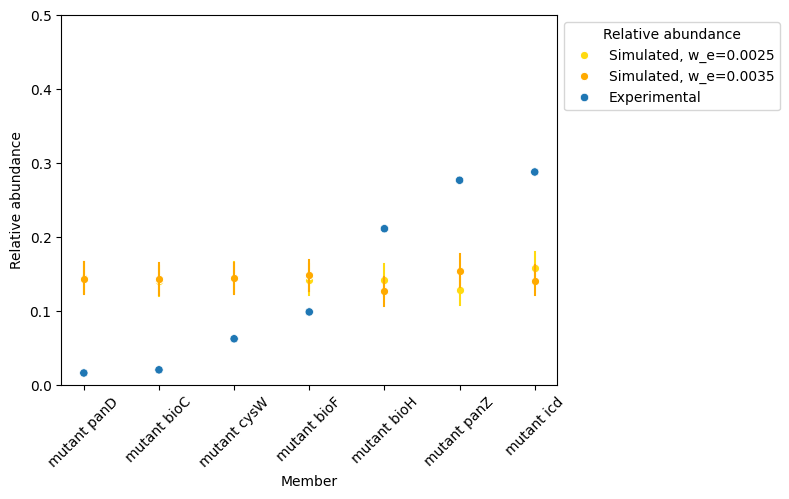

In [96]:
abundance_filled2["w_e"]=0.0035
abundance_filled["w_e"]=0.0025
combined_filled_df = pd.concat([abundance_filled,abundance_filled2])
combined_filled_df = combined_filled_df.merge(exp_abundance,on="member")
combined_filled_df = combined_filled_df.sort_values(["Relative abundance","exp_relative_abundance"])
combined_filled_df["Relative abundance"] = combined_filled_df.w_e.map(lambda x:f"Simulated, w_e={x}")
exp_abundance["Relative abundance"]="Experimental"

fig,ax = plt.subplots(1,1)
sns.lineplot(combined_filled_df,x="member",y="relative_abundance",hue="Relative abundance",err_style="bars",linestyle="",marker="o",ax=ax,palette="Wistia")

sns.scatterplot(exp_abundance,x="member",y="exp_relative_abundance",hue="Relative abundance",ax=ax)
sns.move_legend(ax, 
                "upper left",
                bbox_to_anchor=(1.0, 1.0),
                )

plt.xticks(rotation=45)
member_labels = [" ".join(id_.split("_")) for id_ in exp_abundance.sort_values("exp_relative_abundance").member.values]
ax.set_xticklabels(member_labels)

ax.set_ylim([0,0.5])
ax.set_ylabel("Relative abundance")
ax.set_xlabel("Member")